# Atelier AI - Controlled LightGBM Hyperparameter Search

Compare six declared configurations:
num_leaves {15, 31, 63} × min_child_samples {20, 100}.

All configurations use the same six historical training weeks,
candidate policy, 31 features and validation reference.

Validation period: [2020-09-02, 2020-09-09).
Recommend twelve distinct articles to all 20,000 cohort customers.
Ranking metrics average over all 1,065 target buyers and retain
all 3,428 distinct customer-article targets, including retrieval misses.

Use full-reference validation NDCG@12 for early stopping with
patience 50. Compare configurations using full-reference MAP@12.
V1 and final-confirmation outcomes are outside this search.

This is a retrospective development comparison; see
[the evaluation strategy](../docs/evaluation.md).

In [1]:
from itertools import product
from pathlib import Path
import inspect

import pandas as pd
from IPython.display import display

import atelier_ai
from atelier_ai.workflow import (
    fit_first_ranker,
    fit_ranker_configuration,
)

PROJECT_ROOT = Path(atelier_ai.__file__).resolve().parents[2]

search_grid = pd.DataFrame(
    [
        {
            "method_name": f"lightgbm_leaves_{leaves}_min_{minimum}",
            "num_leaves": leaves,
            "min_child_samples": minimum,
            "output_subdirectory": (
                f"ranker_search/lightgbm_leaves_{leaves}_min_{minimum}"
            ),
        }
        for leaves, minimum in product(
            (15, 31, 63),
            (20, 100),
        )
    ]
)

assert len(search_grid) == 6
assert not search_grid.duplicated(
    ["num_leaves", "min_child_samples"]
).any()
assert search_grid["method_name"].is_unique
assert search_grid["output_subdirectory"].is_unique

display(search_grid)
print("Configurable function:", inspect.signature(fit_ranker_configuration))
print("Initial experiment:", inspect.signature(fit_first_ranker))

,method_name,num_leaves,min_child_samples,output_subdirectory
0,lightgbm_leaves_15_min_20,15,20,ranker_search/lightgbm_leaves_15_min_20
1,lightgbm_leaves_15_min_100,15,100,ranker_search/lightgbm_leaves_15_min_100
2,lightgbm_leaves_31_min_20,31,20,ranker_search/lightgbm_leaves_31_min_20
3,lightgbm_leaves_31_min_100,31,100,ranker_search/lightgbm_leaves_31_min_100
4,lightgbm_leaves_63_min_20,63,20,ranker_search/lightgbm_leaves_63_min_20
5,lightgbm_leaves_63_min_100,63,100,ranker_search/lightgbm_leaves_63_min_100


Configurable function: (root, *, num_leaves, min_child_samples, method_name, output_subdirectory)
Initial experiment: (root)


## 2. Fit the six declared configurations

Use identical training and validation inputs for every configuration.
Only num_leaves and min_child_samples vary.

Each trial selects its boosting iteration using full-reference
validation NDCG@12 with patience 50. Compare the resulting models
using full-reference validation MAP@12.

Keep every validation target in the reference, including retrieval
misses. Neither V1 nor final-confirmation outcomes enter this search.

In [2]:
import json

from atelier_ai.feature_export import (
    file_sha256,
    verify_feature_export,
)
from atelier_ai.workflow import write_json

DATA_ROOT = PROJECT_ROOT / "data/processed/weekly_v1"
SEARCH_ROOT = DATA_ROOT / "ranker_search"
SEARCH_ROOT.mkdir(parents=True, exist_ok=True)

expected_training = json.loads(
    (DATA_ROOT / "training.json").read_text()
)
expected_validation = json.loads(
    (DATA_ROOT / "validation.json").read_text()
)

assert file_sha256(
    DATA_ROOT / "training/rows.parquet"
) == expected_training["row_sha256"]

verify_feature_export(
    PROJECT_ROOT / expected_validation["directory"],
    expected_fingerprint=expected_validation["fingerprint"],
)

search_specs = []
search_rows = []

for trial in search_grid.itertuples(index=False):
    print(f"\nRunning {trial.method_name}", flush=True)

    spec, trial_comparison = fit_ranker_configuration(
        PROJECT_ROOT,
        num_leaves=int(trial.num_leaves),
        min_child_samples=int(trial.min_child_samples),
        method_name=trial.method_name,
        output_subdirectory=trial.output_subdirectory,
    )

    assert spec["training"] == expected_training
    assert spec["validation"] == expected_validation

    if search_specs:
        assert spec["provenance"] == search_specs[0]["provenance"]

    metrics = trial_comparison.loc[
        trial_comparison["method"].eq(trial.method_name)
    ].iloc[0].to_dict()

    assert metrics["recommendation_customers"] == 20_000
    assert metrics["evaluated_customers"] == expected_validation["buyers"]
    assert metrics["target_pairs"] == expected_validation["target_pairs"]

    trial_directory = DATA_ROOT / trial.output_subdirectory
    learning = json.loads(
        (trial_directory / "learning_curve.json").read_text()
    )
    ndcg_values = learning["valid_0"]["ndcg_full_reference_at_12"]

    assert abs(
        metrics["ndcg_at_k"] - max(ndcg_values)
    ) < 1e-12

    search_rows.append(
        {
            **metrics,
            "num_leaves": int(trial.num_leaves),
            "min_child_samples": int(trial.min_child_samples),
            "best_iteration": spec["best_iteration"],
            "fit_seconds": spec["fit_seconds"],
            "score_seconds": spec["score_seconds"],
            "mlflow_run_id": spec["mlflow_run_id"],
        }
    )
    search_specs.append(spec)

    pd.DataFrame(search_rows).to_csv(
        SEARCH_ROOT / "results.csv",
        index=False,
    )

search_results = pd.DataFrame(search_rows)

assert len(search_results) == 6
assert search_results["mlflow_run_id"].is_unique

write_json(
    SEARCH_ROOT / "manifest.json",
    {
        "hyperparameter_search_complete": True,
        "selection_complete": False,
        "v1_evaluated": False,
        "confirmation_evaluated": False,
        "runs": search_specs,
    },
)

print("Completed six configurations.")


Running lightgbm_leaves_15_min_20


/Users/oumar/Developer/portfolio/atelier-ai-project/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[25]	valid_0's ndcg_full_reference_at_12: 0.0368682
[50]	valid_0's ndcg_full_reference_at_12: 0.0384544
[75]	valid_0's ndcg_full_reference_at_12: 0.0373257
[100]	valid_0's ndcg_full_reference_at_12: 0.0372518
Early stopping, best iteration is:
[51]	valid_0's ndcg_full_reference_at_12: 0.0386837
Evaluated only: ndcg_full_reference_at_12

Running lightgbm_leaves_15_min_100


/Users/oumar/Developer/portfolio/atelier-ai-project/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[25]	valid_0's ndcg_full_reference_at_12: 0.0357565
[50]	valid_0's ndcg_full_reference_at_12: 0.0381466
[75]	valid_0's ndcg_full_reference_at_12: 0.0382318
[100]	valid_0's ndcg_full_reference_at_12: 0.0370514
Early stopping, best iteration is:
[73]	valid_0's ndcg_full_reference_at_12: 0.0382841
Evaluated only: ndcg_full_reference_at_12

Running lightgbm_leaves_31_min_20


...

Training until validation scores don't improve for 50 rounds
[25]	valid_0's ndcg_full_reference_at_12: 0.0382923
[50]	valid_0's ndcg_full_reference_at_12: 0.0372471
Early stopping, best iteration is:
[16]	valid_0's ndcg_full_reference_at_12: 0.0389337
Evaluated only: ndcg_full_reference_at_12

Running lightgbm_leaves_63_min_20


/Users/oumar/Developer/portfolio/atelier-ai-project/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[25]	valid_0's ndcg_full_reference_at_12: 0.0394206
[50]	valid_0's ndcg_full_reference_at_12: 0.0388359
Early stopping, best iteration is:
[8]	valid_0's ndcg_full_reference_at_12: 0.0444959
Evaluated only: ndcg_full_reference_at_12

Running lightgbm_leaves_63_min_100


/Users/oumar/Developer/portfolio/atelier-ai-project/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[25]	valid_0's ndcg_full_reference_at_12: 0.0416694
[50]	valid_0's ndcg_full_reference_at_12: 0.0418323
[75]	valid_0's ndcg_full_reference_at_12: 0.0445912
[100]	valid_0's ndcg_full_reference_at_12: 0.0405075
[125]	valid_0's ndcg_full_reference_at_12: 0.0407376
Early stopping, best iteration is:
[75]	valid_0's ndcg_full_reference_at_12: 0.0445912
Evaluated only: ndcg_full_reference_at_12
Completed six configurations.


## 3. Compare validation results

Each heatmap cell represents one fitted hyperparameter configuration.
Its value is full-reference MAP@12 over the same validation buyers.

Compare the six configurations with the three baselines.
Validation differences are development observations; they do not
establish statistical significance or performance on another week.

,method,evaluated_customers,target_pairs,map_at_k,recall_at_k,ndcg_at_k
7,lightgbm_leaves_63_min_20,1065,3428,0.032710,0.059368,0.044496
8,lightgbm_leaves_63_min_100,1065,3428,0.031051,0.063059,0.044591
5,lightgbm_leaves_31_min_20,1065,3428,0.028404,0.057459,0.040445
6,lightgbm_leaves_31_min_100,1065,3428,0.027023,0.056514,0.038934
3,lightgbm_leaves_15_min_20,1065,3428,0.027000,0.054792,0.038684
4,lightgbm_leaves_15_min_100,1065,3428,0.026248,0.055503,0.038284
2,recent_purchases_180d,1065,3428,0.025445,0.055198,0.036811
0,recent_popularity_7d,1065,3428,0.006091,0.022700,0.012546
1,preferred_product_types,1065,3428,0.005346,0.014352,0.009923


,num_leaves,min_child_samples,best_iteration,map_at_k,fit_seconds,score_seconds
4,63,20,8,0.032710,15.620938,0.547851
5,63,100,75,0.031051,32.497337,3.220142
2,31,20,85,0.028404,33.632389,2.304362
3,31,100,16,0.027023,17.001744,0.630084
0,15,20,51,0.027000,22.780476,0.871946
1,15,100,73,0.026248,27.532983,1.180085


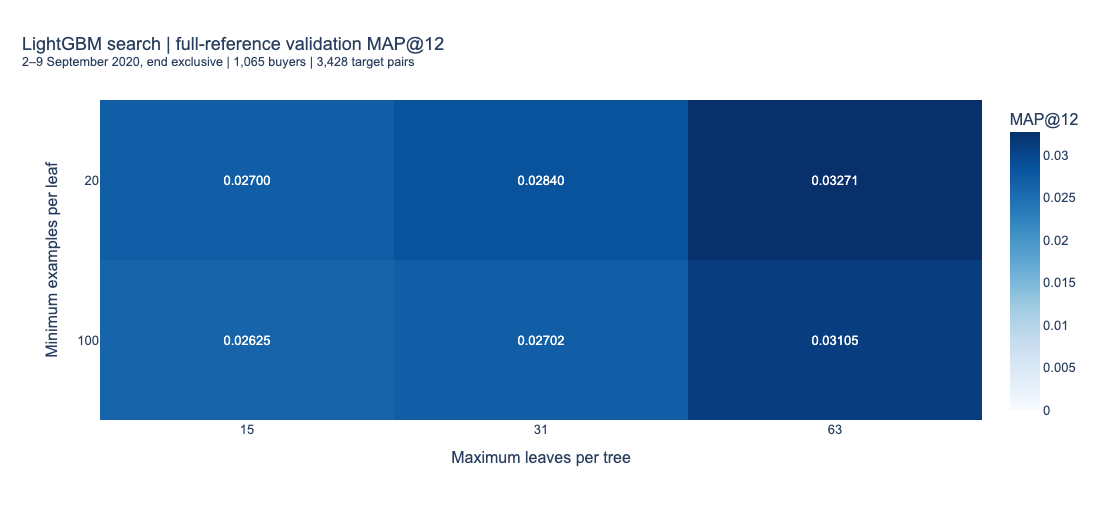

In [3]:
import mlflow
import plotly.express as px

from atelier_ai.notebook_tools import show_figure

search_results = pd.read_csv(SEARCH_ROOT / "results.csv")
baselines = pd.read_csv(DATA_ROOT / "validation/baselines.csv")

comparison_columns = [
    "method",
    "evaluated_customers",
    "target_pairs",
    "map_at_k",
    "recall_at_k",
    "ndcg_at_k",
]

all_methods = pd.concat(
    [
        baselines[comparison_columns],
        search_results[comparison_columns],
    ],
    ignore_index=True,
).sort_values(
    ["map_at_k", "method"],
    ascending=[False, True],
)

display(all_methods)

display(
    search_results[
        [
            "num_leaves",
            "min_child_samples",
            "best_iteration",
            "map_at_k",
            "fit_seconds",
            "score_seconds",
        ]
    ].sort_values("map_at_k", ascending=False)
)

score_matrix = search_results.pivot(
    index="min_child_samples",
    columns="num_leaves",
    values="map_at_k",
).reindex(
    index=[20, 100],
    columns=[15, 31, 63],
)

assert not score_matrix.isna().any().any()

fig = px.imshow(
    score_matrix.to_numpy(),
    x=["15", "31", "63"],
    y=["20", "100"],
    text_auto=".5f",
    aspect="auto",
    zmin=0,
    color_continuous_scale="Blues",
    labels={
        "x": "Maximum leaves per tree",
        "y": "Minimum examples per leaf",
        "color": "MAP@12",
    },
    title=(
        "LightGBM search | full-reference validation MAP@12"
        "<br><sup>2–9 September 2020, end exclusive | "
        "1,065 buyers | 3,428 target pairs</sup>"
    ),
)

figure_name = "tuning_map_heatmap"
show_figure(fig, PROJECT_ROOT, figure_name)

all_methods.to_csv(
    SEARCH_ROOT / "comparison_with_baselines.csv",
    index=False,
)

for spec in search_specs:
    with mlflow.start_run(run_id=spec["mlflow_run_id"]):
        mlflow.log_artifact(
            str(SEARCH_ROOT / "results.csv"),
            artifact_path="search_comparison",
        )
        mlflow.log_artifact(
            str(PROJECT_ROOT / f"artifacts/figures/{figure_name}.png"),
            artifact_path="search_comparison",
        )

## 4. Candidate configuration for next stage

Select num_leaves=63 and min_child_samples=20 using the highest
full-reference validation MAP@12 among the six declared configurations.

The selected model reaches MAP@12=0.032710, Recall@12=0.059368
and NDCG@12=0.044496. Its validation-selected boosting iteration is 8.

The 63-leaf / minimum-100 configuration has slightly higher NDCG
and Recall, but lower MAP. Selection follows the previously declared
primary metric.

The best baseline, recent personal purchases, reaches MAP@12=0.025445.
All comparisons use the same 1,065 validation buyers and retain
all 3,428 distinct target pairs, including retrieval misses.

This configuration is the reference candidate for stage-8 diagnostics.
Final method selection, uncertainty assessment, feature ablations,
train-plus-validation refitting and V1 evaluation remain pending.

In [4]:
search_results = pd.read_csv(SEARCH_ROOT / "results.csv")
baselines = pd.read_csv(DATA_ROOT / "validation/baselines.csv")

ordered_candidates = search_results.sort_values(
    ["map_at_k", "num_leaves", "min_child_samples"],
    ascending=[False, True, False],
)

winner = ordered_candidates.iloc[0]
best_baseline = baselines.sort_values(
    ["map_at_k", "method"],
    ascending=[False, True],
).iloc[0]

if winner["map_at_k"] <= best_baseline["map_at_k"]:
    raise ValueError(
        "A baseline leads or ties; review the candidate selection."
    )

winner_directory = SEARCH_ROOT / winner["method"]
winner_spec = json.loads(
    (winner_directory / "manifest.json").read_text()
)

candidate = {
    "status": "candidate_for_stage8",
    "selection_metric": "full_reference_validation_map_at_12",
    "method": winner["method"],
    "parameters": winner_spec["parameters"],
    "validation_best_iteration": int(winner["best_iteration"]),
    "validation_metrics": {
        name: float(winner[name])
        for name in ["map_at_k", "recall_at_k", "ndcg_at_k"]
    },
    "model_file": str(
        (winner_directory / "model.txt").relative_to(PROJECT_ROOT)
    ),
    "model_sha256": winner_spec["model_sha256"],
    "mlflow_run_id": winner["mlflow_run_id"],
    "training": winner_spec["training"],
    "validation": winner_spec["validation"],
    "final_method_frozen": False,
    "final_refit_complete": False,
    "v1_evaluated": False,
    "confirmation_evaluated": False,
}

write_json(
    SEARCH_ROOT / "selected_candidate.json",
    candidate,
)

campaign = json.loads(
    (SEARCH_ROOT / "manifest.json").read_text()
)
campaign.update(
    {
        "selection_complete": True,
        "selection_scope": "stage7_validation_candidate",
        "final_method_frozen": False,
        "selected_candidate": "selected_candidate.json",
    }
)
write_json(SEARCH_ROOT / "manifest.json", campaign)

with mlflow.start_run(run_id=candidate["mlflow_run_id"]):
    mlflow.log_dict(candidate, "stage7_selected_candidate.json")

display(
    pd.Series(
        {
            "candidate": candidate["method"],
            "validation_best_iteration": (
                candidate["validation_best_iteration"]
            ),
            **candidate["validation_metrics"],
        }
    )
)

candidate                    lightgbm_leaves_63_min_20
validation_best_iteration                            8
map_at_k                                       0.03271
recall_at_k                                   0.059368
ndcg_at_k                                     0.044496
dtype: object